# CS-412 Application Project: Credit Card Fraud Detection
**Student:** Individual project  
**Question:** How do Logistic Regression, Random Forest, and XGBoost compare on imbalanced credit-card transaction data?  
**Data:** Original ULB/Kaggle `creditcard.csv`, not the 2023 balanced dataset.  
**Environment:** VS Code + Conda, running locally in this GitHub repository.

**This notebook is your executable starting point** for the intermediate report. It computes dataset checks, stratified train/validation/test splits, three initial classifiers, metrics, figures, and a first class-weighted experiment.

**Evaluation discipline:** split before learning any transformations; keep the test set untouched until final experiments. This notebook reports **validation** performance. Do not present results before running the notebook on the actual CSV.

Source: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

## Step 1 — Configure your Conda environment and import tools

Before running, open the **repository folder** in VS Code, create the environment using `conda env create -f environment.yml`, and activate it with `conda activate cs412-fraud`. In VS Code, open this `.ipynb` and choose the **Python (cs412-fraud)** kernel (or the corresponding Conda interpreter). The Python and Jupyter VS Code extensions should be installed.

No `pip install` or Colab setup cells are required. A CPU is sufficient. See the repository `README.md` for the full setup steps.

In [3]:
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay)
from xgboost import XGBClassifier

RANDOM_STATE = 42

# VS Code can set the notebook working directory to the repository root or to
# the notebooks/ folder. Search upward for data/creditcard.csv to support both.
def locate_project_root(start: Path) -> Path:
    start = start.resolve()
    candidates = (start, *start.parents)
    for candidate in candidates:
        if (candidate / 'data' / 'creditcard.csv').is_file():
            return candidate
    searched = '\n'.join(str(p / 'data' / 'creditcard.csv') for p in candidates)
    raise FileNotFoundError(
        'Cannot find data/creditcard.csv. Open the cloned repository folder in '
        'VS Code and make sure the original Kaggle CSV is in its data/ folder. '
        f'Current working directory: {start}\nPaths checked:\n{searched}'
    )

PROJECT_ROOT = locate_project_root(Path.cwd())
DATA_PATH = PROJECT_ROOT / 'data' / 'creditcard.csv'
OUTPUT_DIR = PROJECT_ROOT / 'results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Repository root: {PROJECT_ROOT}')
print(f'CSV: {DATA_PATH}')
print(f'Outputs: {OUTPUT_DIR}')

Repository root: K:\My Drive\Classes\CS-412\Project_Repo\CS412_Project_Credit_Card_Fraud_Detection
CSV: K:\My Drive\Classes\CS-412\Project_Repo\CS412_Project_Credit_Card_Fraud_Detection\data\creditcard.csv
Outputs: K:\My Drive\Classes\CS-412\Project_Repo\CS412_Project_Credit_Card_Fraud_Detection\results


## Step 2 — Load the CSV already saved in your repository

Download the **original** [ULB credit card fraud dataset on Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) and extract `creditcard.csv` into your cloned repository's `data/` folder (as you have already done).

The notebook uses `PROJECT_ROOT / 'data' / 'creditcard.csv'`. It works whether VS Code's notebook working directory is the repository root or the `notebooks/` folder. **No upload dialog, Google Drive, or Colab is involved.**

The `.gitignore` keeps the data CSV out of version control.

In [4]:
print('Loading:', DATA_PATH)
df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
display(df_raw.head())

Loading: K:\My Drive\Classes\CS-412\Project_Repo\CS412_Project_Credit_Card_Fraud_Detection\data\creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 3 — Describe and validate the dataset
This is the first material for your Intermediate Report's **Data Description** section.

Missing cells: 0
Exact duplicate rows: 1081


,Class,Transactions,Percent
0,Legitimate (0),284315,99.827251
1,Fraud (1),492,0.172749


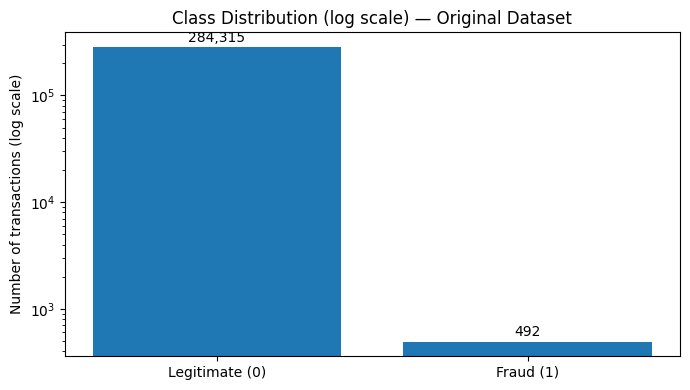

In [5]:
expected = {'Time', 'Amount', 'Class'} | {f'V{i}' for i in range(1, 29)}
assert set(df_raw.columns) == expected, 'Unexpected columns: verify you downloaded the correct dataset.'
assert set(df_raw['Class'].unique()) == {0, 1}, 'Class should contain labels 0 and 1.'

counts_raw = df_raw['Class'].value_counts().sort_index()
summary = pd.DataFrame({'Class': ['Legitimate (0)', 'Fraud (1)'],
                        'Transactions': [int(counts_raw[0]), int(counts_raw[1])]})
summary['Percent'] = 100 * summary['Transactions'] / len(df_raw)
print('Missing cells:', int(df_raw.isna().sum().sum()))
print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
display(summary)
summary.to_csv(OUTPUT_DIR / 'raw_class_distribution.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary['Class'], summary['Transactions'])
ax.set_yscale('log')
ax.set_title('Class Distribution (log scale) — Original Dataset')
ax.set_ylabel('Number of transactions (log scale)')
for i, count in enumerate(summary['Transactions']):
    ax.text(i, count * 1.12, f'{count:,}', ha='center')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=160)
plt.show()

## Step 4 — Remove exact duplicates, and split before preprocessing
**Why:** identical duplicate records can otherwise be placed in both training and validation/test portions. We keep a record of how many were removed.

We use a stratified **60% train / 20% validation / 20% held-out test** split so that rare fraud events occur in every partition. No data-scaling or sampling method sees validation or test observations during fitting. The test data is not evaluated in this intermediate-stage notebook.

In [6]:
num_raw_rows = len(df_raw)
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f'Removed {num_raw_rows - len(df):,} exact duplicate rows; retained {len(df):,}.')

X = df.drop(columns='Class')
y = df['Class'].astype(int)

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test (held out)'],
    'Rows': [len(y_train), len(y_val), len(y_test)],
    'Fraud': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
})
split_summary['Fraud_Rate_Percent'] = 100 * split_summary['Fraud'] / split_summary['Rows']
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / 'split_summary.csv', index=False)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

Removed 1,081 exact duplicate rows; retained 283,726.


,Split,Rows,Fraud,Fraud_Rate_Percent
0,Train,170235,284,0.166828
1,Validation,56745,94,0.165653
2,Test (held out),56746,95,0.167413


## Step 5 — Train the three baseline models
All methods train on exactly the same training records and are evaluated on the same validation records. Logistic Regression uses scaling inside an sklearn pipeline (the scaler is fitted **only** on train data). Random Forest and XGBoost do not require scaling here.

Model choices are a straightforward starting point, **not a tuned optimum**. Some cells may take a couple of minutes on a free CPU runtime.

In [7]:
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=120, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=160, max_depth=4, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        tree_method='hist', eval_metric='logloss',
        random_state=RANDOM_STATE, n_jobs=2
    ),
}

validation_predictions = {}
for model_name, model in models.items():
    print(f'Training {model_name}...')
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.50).astype(int)
    validation_predictions[model_name] = (prob, pred)
    print(f'  Done: {model_name}.')

Training Logistic Regression...
  Done: Logistic Regression.
Training Random Forest...
  Done: Random Forest.
Training XGBoost...
  Done: XGBoost.


## Step 6 — Report evaluation metrics and confusion matrices
**Key:** in this project, accuracy alone is misleading because a model predicting "not fraud" for every transaction already achieves roughly 99.8% accuracy on the unmodified source distribution. Focus on precision, recall, F1, ROC-AUC and **Average Precision (AP)** as the operational summary of the precision-recall curve. Note AP is a commonly used PR summary, not identical to trapezoidal PR-AUC.

,Model,Precision,Recall,F1,ROC_AUC,Average_Precision_PR,True_Positive,False_Positive,True_Negative,False_Negative
2,XGBoost,0.9524,0.8511,0.8989,0.9740,0.8860,80,4,56647,14
1,Random Forest,0.9048,0.8085,0.8539,0.9499,0.8770,76,8,56643,18
0,Logistic Regression,0.8767,0.6809,0.7665,0.9733,0.8023,64,9,56642,30


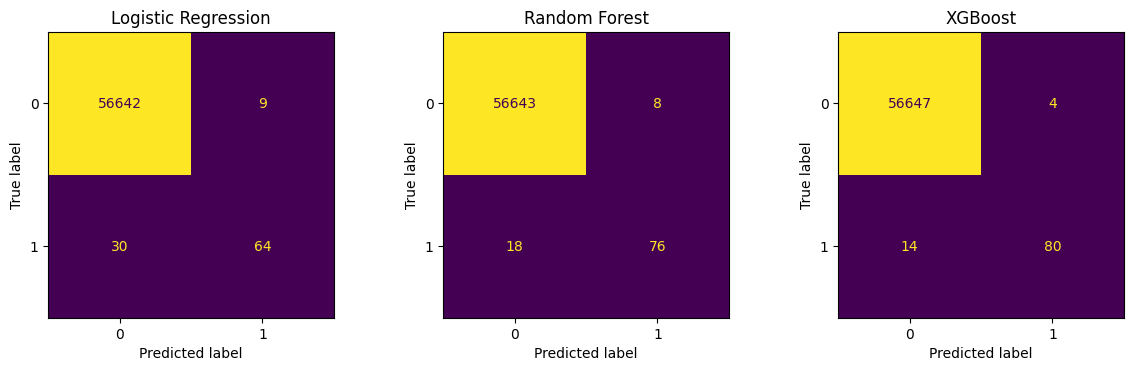

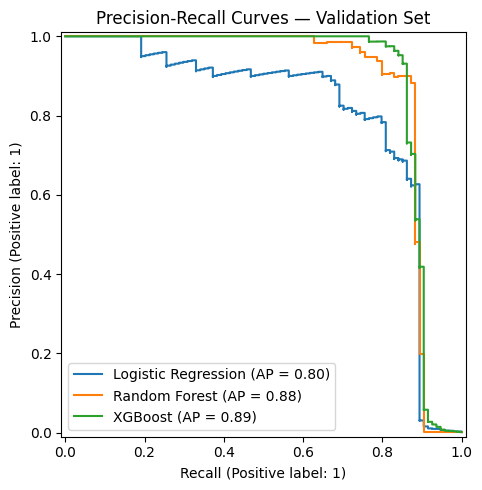

In [8]:
def make_metrics(name, y_true, probabilities, predictions):
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'Model': name,
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'Average_Precision_PR': average_precision_score(y_true, probabilities),
        'True_Positive': int(tp), 'False_Positive': int(fp),
        'True_Negative': int(tn), 'False_Negative': int(fn)
    }

metrics_rows = [make_metrics(n, y_val, prob, pred)
                for n, (prob, pred) in validation_predictions.items()]
metrics = pd.DataFrame(metrics_rows).sort_values('Average_Precision_PR', ascending=False)
display(metrics.round(4))
metrics.to_csv(OUTPUT_DIR / 'baseline_validation_metrics.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, (name, (prob, pred)) in zip(axes, validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=[0, 1], ax=ax,
                                            colorbar=False, values_format='d')
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'baseline_confusion_matrices.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, (prob, pred) in validation_predictions.items():
    PrecisionRecallDisplay.from_predictions(y_val, prob, ax=ax, name=name)
ax.set_title('Precision-Recall Curves — Validation Set')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'baseline_precision_recall_curves.png', dpi=160)
plt.show()

## Step 7 — Begin an imbalance-handling experiment: weighted Logistic Regression
This first controlled experiment changes only `class_weight` for Logistic Regression. It is a useful first step before adding sampling/SMOTE in the next phase. Its validation metrics should be compared to the standard Logistic Regression baseline above.

In [9]:
weighted_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
)
weighted_lr.fit(X_train, y_train)
weighted_probs = weighted_lr.predict_proba(X_val)[:, 1]
weighted_preds = (weighted_probs >= 0.5).astype(int)
weighted_row = make_metrics('Logistic Regression (class_weight=balanced)',
                            y_val, weighted_probs, weighted_preds)
compare = pd.concat([metrics.loc[metrics.Model == 'Logistic Regression'],
                     pd.DataFrame([weighted_row])], ignore_index=True)
display(compare.round(4))
compare.to_csv(OUTPUT_DIR / 'class_weight_experiment.csv', index=False)

,Model,Precision,Recall,F1,ROC_AUC,Average_Precision_PR,True_Positive,False_Positive,True_Negative,False_Negative
0,Logistic Regression,0.8767,0.6809,0.7665,0.9733,0.8023,64,9,56642,30
1,Logistic Regression (class_weight=balanced),0.0538,0.9043,0.1016,0.9790,0.7876,85,1495,55156,9


## Step 8 — What to record in the intermediate report
Copy **real printed output** from this notebook into your report:
- raw shape, target counts, missing values, exact duplicate count;
- cleaned size and the train/validation/test partition sizes;
- baseline validation metrics table and the confusion-matrix figure;
- a brief observation on the weighted Logistic Regression comparison;
- limitations and remaining work (SMOTE or undersampling; fair settings; validation-only threshold tuning; final held-out test and repeated runs).

**Important:** You have not evaluated the test set here. Keep it untouched for the final selection stage to avoid optimistic estimates.

All tables and figures are written to `<repository>/results/`. The final cell also creates `CS412_intermediate_outputs.zip` in the repository root. In VS Code, open the `results/` folder to inspect files; you do not need to download anything from a cloud notebook. Commit the notebook and results you want to document to GitHub; do not commit `creditcard.csv`.

In [10]:
from zipfile import ZipFile

archive_path = PROJECT_ROOT / 'CS412_intermediate_outputs.zip'
with ZipFile(archive_path, 'w') as zf:
    for p in sorted(OUTPUT_DIR.glob('*')):
        if p.is_file():
            zf.write(p, arcname=f'results/{p.name}')
print(f'Created {archive_path}')
print('Report artifacts:', [p.name for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()])

Created K:\My Drive\Classes\CS-412\Project_Repo\CS412_Project_Credit_Card_Fraud_Detection\CS412_intermediate_outputs.zip
Report artifacts: ['baseline_confusion_matrices.png', 'baseline_precision_recall_curves.png', 'baseline_validation_metrics.csv', 'class_distribution.png', 'class_weight_experiment.csv', 'raw_class_distribution.csv', 'split_summary.csv']
